# Шаблон бэктеста QuantResearch

Шаблон Jupyter Notebook для исследования и запуска бэктестов в **Backtrader**. 
Запускать из окружения QuantResearch (`.venv`).

## 0. Результаты и заметки

На следующем этапе добавим метрики, сохранение результатов в SQLite и сравнение запусков. Пока можно записывать выводы эксперимента здесь.

**Гипотеза:** …

**Выводы:** …

In [5]:
#Загружает расширение autoreload
%load_ext autoreload
#Включает автоматическую перезагрузку импортированных модулей перед выполнением каждой ячейки
%autoreload 2
%matplotlib inline

## 1. Импорт библиотек

In [1]:
import sys
print(sys.executable)

/Volumes/DataD/AlgorithmicTrading/QuantResearch/.venv/bin/python


In [2]:
import backtrader as bt
import pandas as pd
import numpy as np

from IPython.display import display, HTML
from lightweight_charts import Chart
import matplotlib.pyplot as plt
# %matplotlib inlinefrom

In [3]:
from FinamPy import FinamPy
from MOEXPy import MOEXPy
from FinLabPy.Core import Symbol

from finam_commission import FinamCommission

## 3. Исторические данные

Backtrader ожидает DataFrame с индексом `DatetimeIndex` и столбцами `open`, `high`, `low`, `close`, `volume`.

In [140]:
df = pd.read_csv('../Data/TQBR.CHMF_D1.txt', sep='\t')
df.head()

,datetime,open,high,low,close,volume
0,22.06.2005 00:00,220.0,220.0,217.0,219.0,64
1,23.06.2005 00:00,219.0,230.0,219.0,223.0,43
2,24.06.2005 00:00,225.0,227.0,216.0,216.0,18
3,27.06.2005 00:00,213.5,213.5,211.0,211.0,6
4,28.06.2005 00:00,214.0,216.0,208.0,208.0,43


In [141]:
df['datetime']  = pd.to_datetime(df['datetime'], format='%d.%m.%Y %H:%M').astype('datetime64[ns]')
df = df.set_index('datetime')
df.head()

,open,high,low,close,volume
datetime,,,,,
2005-06-22,220.0,220.0,217.0,219.0,64
2005-06-23,219.0,230.0,219.0,223.0,43
2005-06-24,225.0,227.0,216.0,216.0,18
2005-06-27,213.5,213.5,211.0,211.0,6
2005-06-28,214.0,216.0,208.0,208.0,43


In [147]:
print('Начало:', df.index.min())
print('Конец:', df.index.max())
print('Количество свечей:', len(df))

Начало: 2005-06-22 00:00:00
Конец: 2026-03-17 00:00:00
Количество свечей: 5267


In [145]:
import pandas as pd
from lightweight_charts import Chart

timeframe = 'D1'
title = 'CHMF'


chart = Chart()

# Тикер и таймфрейм в верхней панели
chart.topbar.textbox('symbol', title)
chart.topbar.textbox('timeframe', timeframe)

# Отображение OHLCV
chart.legend(visible=True)

# Для дневного таймфрейма скрываем часы
chart.time_scale(
    time_visible=False,
    seconds_visible=False
)

chart.set(df)
chart.show()

In [146]:
chart.exit()

## 3. Стратегия

Пример стратегии без выставления заявок. Добавьте торговую логику в метод `next`, когда будете готовы.

In [25]:
class ResearchStrategy(bt.Strategy):
    params = (("sma_period", SMA_PERIOD),)

    def __init__(self):
        self.sma = bt.indicators.SimpleMovingAverage(
            self.data.close, period=self.p.sma_period
        )

    def next(self):
        # TODO: добавить условия входа/выхода и управление риском
        pass


## 2. Параметры эксперимента

In [8]:
INITIAL_CASH = 100_000.0
COMMISSION = 0.001
SMA_PERIOD = 20

## 5. Запуск бэктеста

In [117]:
from IPython.display import display, HTML
# %matplotlib inline
import matplotlib.pyplot as plt

Стартовый капитал: 100,000.00
Конечный капитал: 100,000.00


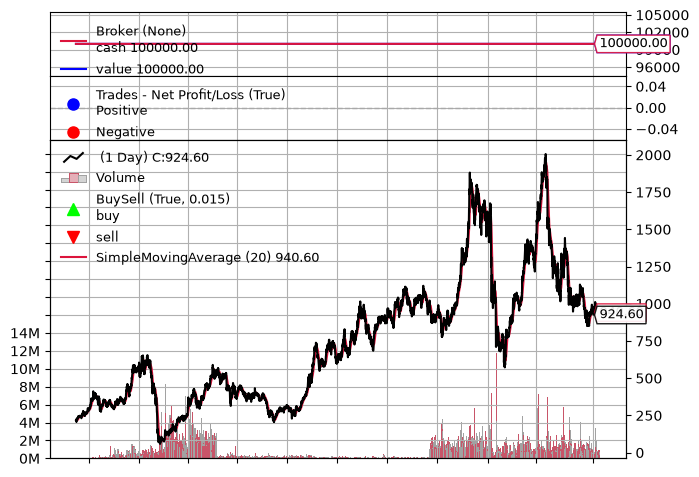

In [118]:
cerebro = bt.Cerebro()
cerebro.addstrategy(ResearchStrategy, sma_period=SMA_PERIOD)
cerebro.adddata(bt.feeds.PandasData(dataname=df))
cerebro.broker.setcash(INITIAL_CASH)
# cerebro.broker.setcommission(commission=COMMISSION)
cerebro.broker.addcommissioninfo(FinamCommission()) 

start_value = cerebro.broker.getvalue()
results = cerebro.run()
end_value = cerebro.broker.getvalue()
print(f"Стартовый капитал: {start_value:,.2f}")
print(f"Конечный капитал: {end_value:,.2f}")
cerebro.plot(iplot=False)
plt.show()